In [1]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde
from skimage import morphology, measure
from skimage.morphology import skeletonize
from scipy import ndimage as ndi
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.stats import spearmanr
import csv

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.thickness import _walk_to_mask_edge, caliper_length, gaussian, thickness_m1
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [2]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625





Loading cached filtered B ...
Loading cached filtered E ...
J.E : mean = 5.968e-07, min = -4.380e-02, max = 3.826e-02


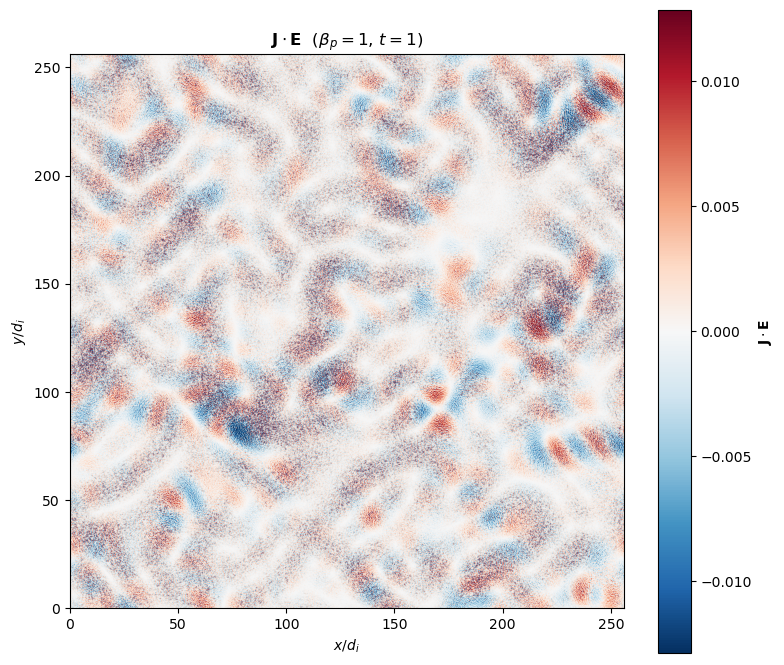

In [9]:
# ============================================================
#  J . E  (electromagnetic work rate) for ONE beta
#  ------------------------------------------------------------
#  Filters B and E (same MIF params), builds J = curl(B) from the
#  filtered B, forms J.E = Jx*Ex + Jy*Ey + Jz*Ez, and plots the map.
#  Positive (red) = field -> plasma (dissipation/heating),
#  negative (blue) = plasma -> field.
#
#  Assumes E files are named like your B files: Ex_ApJ_t{time}.h5 etc.
#  Needs from your session: iterative_filtering3D, partial_x_fft, partial_y_fft
# ============================================================

# -----------------------------
# USER SETTINGS
# -----------------------------
beta    = 1                        # one run only
time    = 1                      # one snapshot
sim_tag = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"
cache_dir = str(CACHE / "filtered_cache")
os.makedirs(cache_dir, exist_ok=True)

px_per_di = 16.0
dx = dy   = 0.0625

# filter parameters for this beta (same table as your detection)
if beta == 0.0625:
    n_iter, Xi = 1, 1.6
elif beta == 1:
    n_iter, Xi = 2, 2.0
else:
    n_iter, Xi = 3, 2.0


def load(tag):
    with h5py.File(f"{base_path}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


# -----------------------------
# FILTER B  (reuses your existing cache if present)
# -----------------------------
cache_B = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
if os.path.exists(cache_B):
    print("Loading cached filtered B ...")
    d = np.load(cache_B)
    Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
else:
    print("Filtering B (slow) ...")
    Bx_f, By_f, Bz_f = iterative_filtering3D(load("Bx"), load("By"), load("Bz"), n_iter, Xi=Xi)
    np.savez_compressed(cache_B, Bx=Bx_f, By=By_f, Bz=Bz_f)

# -----------------------------
# FILTER E
# -----------------------------
cache_E = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}_E.npz"
if os.path.exists(cache_E):
    print("Loading cached filtered E ...")
    d = np.load(cache_E)
    Ex_f, Ey_f, Ez_f = d["Ex"], d["Ey"], d["Ez"]
else:
    print("Filtering E (slow) ...")
    Ex_f, Ey_f, Ez_f = iterative_filtering3D(load("Ex"), load("Ey"), load("Ez"), n_iter, Xi=Xi)
    np.savez_compressed(cache_E, Ex=Ex_f, Ey=Ey_f, Ez=Ez_f)

# -----------------------------
# CURRENT DENSITY from filtered B  (J = curl B, 2D)
# -----------------------------
Jx = partial_y_fft(Bz_f, dx)
Jy = -partial_x_fft(Bz_f, dy)
Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)

# -----------------------------
# J . E
# -----------------------------
JdotE = Jx * Ex_f + Jy * Ey_f + Jz * Ez_f
print(f"J.E : mean = {JdotE.mean():.3e}, min = {JdotE.min():.3e}, max = {JdotE.max():.3e}")

# -----------------------------
# PLOT  (diverging colours centred on zero)
# -----------------------------
vlim   = np.percentile(np.abs(JdotE), 99)              # symmetric limits, ignore outliers
extent = [0, JdotE.shape[0] / px_per_di, 0, JdotE.shape[1] / px_per_di]

plt.figure(figsize=(8, 7))
im = plt.imshow(JdotE.T, origin="lower", cmap="RdBu_r",
                vmin=-vlim, vmax=vlim, extent=extent)
plt.colorbar(im, label=r"$\mathbf{J}\cdot\mathbf{E}$")
plt.xlabel(r"$x/d_i$"); plt.ylabel(r"$y/d_i$")
plt.title(rf"$\mathbf{{J}}\cdot\mathbf{{E}}$  ($\beta_p={beta}$, $t={time}$)")
plt.tight_layout()
plt.savefig(RESULTS / f"JdotE_beta{beta}_t{time}.png", dpi=300)
plt.show()

Loading cached filtered B ...
Loading cached filtered E ...

=== beta_p = 1, t = 40 ===
area filling factor        : 2.01 %
dissipation filling factor : 4.49 %   (positive J.E)
net J.E filling factor     : -106.96 %
concentration (diss/area)  : x2.2
<J.E> inside / outside     : -25.2


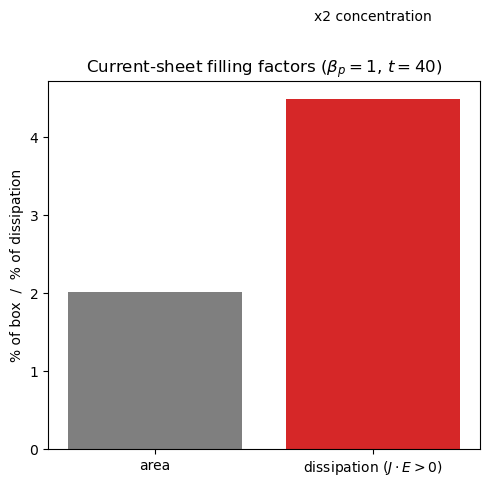

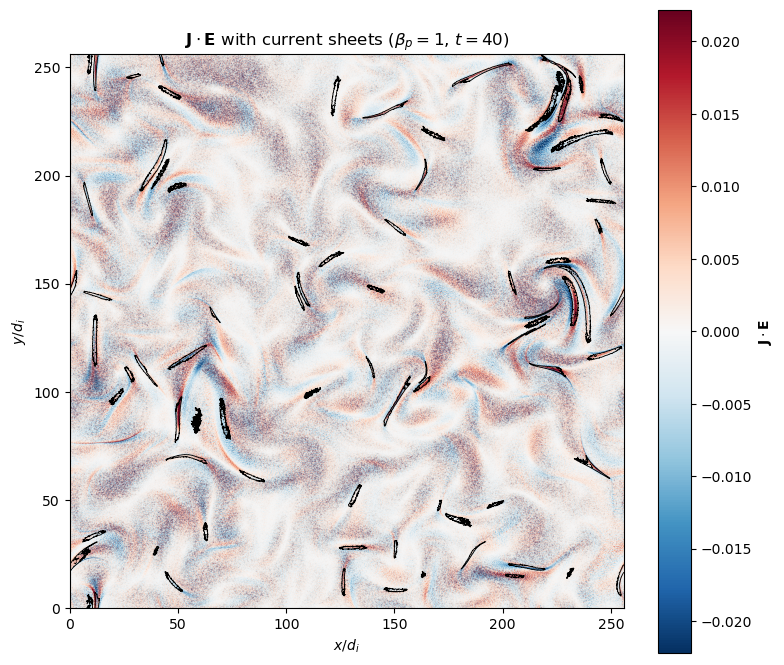

In [3]:
# ============================================================
#  J . E inside the current sheets  +  filling factors  (ONE beta)
#  ------------------------------------------------------------
#  Filters B and E, builds J = curl(B) from filtered B, forms J.E,
#  detects the current sheets (your pipeline), then compares:
#     - area filling factor  : fraction of the box occupied by sheets
#     - dissipation filling  : fraction of the (positive) J.E inside sheets
#  concentration = dissipation / area  >> 1 means sheets dominate dissipation.
#
#  Assumes E files are named like your B files: Ex_ApJ_t{time}.h5 etc.
#  Needs from your session: iterative_filtering3D, partial_x_fft,
#                           partial_y_fft, detect_current_sheets
# ============================================================

# -----------------------------
# USER SETTINGS
# -----------------------------
beta    = 1                        # one run only
time    = 40
sim_tag = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"
cache_dir = str(CACHE / "filtered_cache")
os.makedirs(cache_dir, exist_ok=True)

px_per_di = 16.0
dx = dy   = 0.0625

# filter parameters for this beta (same table as your detection)
if beta == 0.0625:
    n_iter, Xi = 1, 1.6
elif beta == 1:
    n_iter, Xi = 2, 2.0
else:
    n_iter, Xi = 3, 2.0


# -----------------------------
# FILTER B  (reuses your existing cache if present)
# -----------------------------
cache_B = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
if os.path.exists(cache_B):
    print("Loading cached filtered B ...")
    d = np.load(cache_B)
    Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
else:
    print("Filtering B (slow) ...")
    Bx_f, By_f, Bz_f = iterative_filtering3D(load("Bx"), load("By"), load("Bz"), n_iter, Xi=Xi)
    np.savez_compressed(cache_B, Bx=Bx_f, By=By_f, Bz=Bz_f)

# -----------------------------
# FILTER E
# -----------------------------
cache_E = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}_E.npz"
if os.path.exists(cache_E):
    print("Loading cached filtered E ...")
    d = np.load(cache_E)
    Ex_f, Ey_f, Ez_f = d["Ex"], d["Ey"], d["Ez"]
else:
    print("Filtering E (slow) ...")
    Ex_f, Ey_f, Ez_f = iterative_filtering3D(load("Ex"), load("Ey"), load("Ez"), n_iter, Xi=Xi)
    np.savez_compressed(cache_E, Ex=Ex_f, Ey=Ey_f, Ez=Ez_f)

# -----------------------------
# CURRENT DENSITY from filtered B, and J.E from filtered E
# -----------------------------
Jx = partial_y_fft(Bz_f, dx)
Jy = -partial_x_fft(Bz_f, dy)
Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
JdotE = Jx * Ex_f + Jy * Ey_f + Jz * Ez_f

# -----------------------------
# CURRENT SHEET DETECTION  (mask from |Jz|, your pipeline)
# -----------------------------
J2 = np.abs(Jz)
sheets = detect_current_sheets(J2)
mask = np.zeros_like(J2)
for sheet in sheets:
    for (i, j) in sheet:
        mask[i, j] = 1
struct = morphology.disk(1)
mask = morphology.binary_opening(mask, struct)
mask = morphology.binary_closing(mask, struct)
m = morphology.remove_small_objects(mask.astype(bool), min_size=500)

# -----------------------------
# FILLING FACTORS
# -----------------------------
pos    = JdotE > 0                                   # positive J.E = field -> plasma
f_area = m.mean()                                    # fraction of box that is sheet
f_diss = JdotE[m & pos].sum() / JdotE[pos].sum()     # share of positive work inside sheets
f_net  = JdotE[m].sum() / JdotE.sum()                # share of NET J.E inside sheets
conc   = f_diss / f_area                             # concentration factor

print(f"\n=== beta_p = {beta}, t = {time} ===")
print(f"area filling factor        : {100*f_area:.2f} %")
print(f"dissipation filling factor : {100*f_diss:.2f} %   (positive J.E)")
print(f"net J.E filling factor     : {100*f_net:.2f} %")
print(f"concentration (diss/area)  : x{conc:.1f}")
print(f"<J.E> inside / outside     : {JdotE[m].mean()/JdotE[~m].mean():.1f}")

# -----------------------------
# BAR: area vs dissipation filling factor
# -----------------------------
plt.figure(figsize=(5, 5))
bars = plt.bar(["area", r"dissipation ($J\cdot E>0$)"],
               [100*f_area, 100*f_diss], color=["tab:gray", "tab:red"])
plt.text(1, 100*f_diss + 1, f"x{conc:.0f} concentration", ha="center", fontsize=10)
plt.ylabel("% of box  /  % of dissipation")
plt.title(rf"Current-sheet filling factors ($\beta_p={beta}$, $t={time}$)")
plt.tight_layout()
plt.savefig(RESULTS / f"filling_factor_beta{beta}_t{time}.png", dpi=300)
plt.show()

# -----------------------------
# MAP: J.E with current-sheet contours
# -----------------------------
vlim   = np.percentile(np.abs(JdotE), 99)
extent = [0, JdotE.shape[0]/px_per_di, 0, JdotE.shape[1]/px_per_di]

plt.figure(figsize=(8, 7))
im = plt.imshow(JdotE.T, origin="lower", cmap="RdBu_r",
                vmin=-vlim, vmax=vlim, extent=extent)
plt.colorbar(im, label=r"$\mathbf{J}\cdot\mathbf{E}$")
plt.contour(m.T, levels=[0.5], colors="black", linewidths=0.6, extent=extent)
plt.xlabel(r"$x/d_i$"); plt.ylabel(r"$y/d_i$")
plt.title(rf"$\mathbf{{J}}\cdot\mathbf{{E}}$ with current sheets ($\beta_p={beta}$, $t={time}$)")
plt.tight_layout()
plt.savefig(RESULTS / f"JdotE_with_sheets_beta{beta}_t{time}.png", dpi=300)
plt.show()

Loading cached filtered B ...
Loading cached filtered E ...
[t=200] regions (8-connectivity): 188


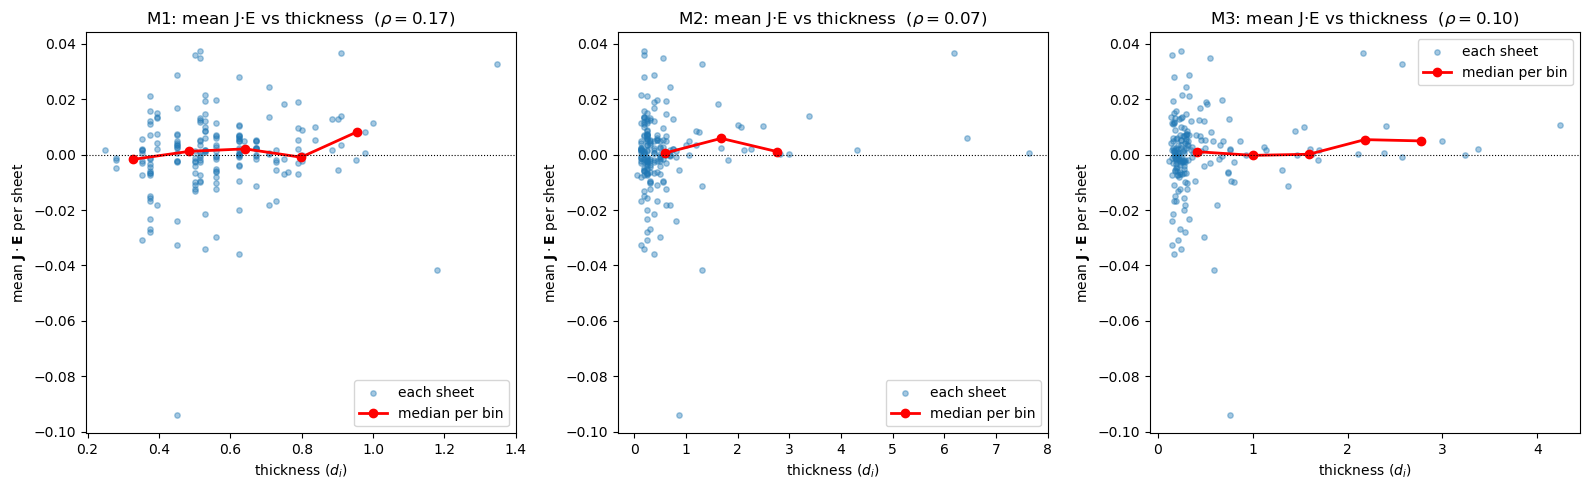


=== J.E vs thickness  (beta_p=1, t=200) ===
 method     N   rho(mean)   rho(sum)   rho(|.|)
     M1   188       0.166      0.181      0.133
     M2   188       0.066      0.094      0.108
     M3   186       0.101      0.110     -0.069

Saved figure and M1 CSV for beta=1, t=200.


In [4]:
# ============================================================
#  J . E  vs  current-sheet THICKNESS  (one beta)
#  ------------------------------------------------------------
#  CONNECTIVITY: a SINGLE 8-connected labeling (measure.label, connectivity=2)
#  is used by all three thickness methods AND by J.E, so every per-sheet
#  quantity shares one region index space. (Previously M1 used skimage 8-conn
#  while M2/M3 used scipy 4-conn, so they measured different sheets.)
#
#  Filters B and E, builds J.E, detects the sheets, runs YOUR thickness
#  methods (M1/M2/M3, algorithms unchanged), then pairs a per-sheet J.E with
#  each thickness and plots J.E vs thickness (scatter + binned medians).
#
#  Per-sheet J.E measured three ways: mean signed, integrated sum, mean |.|.
#  Assumes E files named like your B files: Ex_ApJ_t{time}.h5 etc.
#  Needs from your session: iterative_filtering3D, partial_x_fft, partial_y_fft,
#                           detect_current_sheets
# ============================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
from scipy.stats import spearmanr

# -----------------------------
# USER SETTINGS
# -----------------------------
beta    = 1                        # one run only
time    = 200
sim_tag = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"
cache_dir = str(CACHE / "filtered_cache")
os.makedirs(cache_dir, exist_ok=True)

px_per_di = 16.0
dx = dy   = 0.0625

if beta == 0.0625:
    n_iter, Xi = 1, 1.6
elif beta == 1:
    n_iter, Xi = 2, 2.0
else:
    n_iter, Xi = 3, 2.0


# -----------------------------
# FILTER B (reuses your existing cache) and E
# -----------------------------
cache_B = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
if os.path.exists(cache_B):
    print("Loading cached filtered B ...")
    d = np.load(cache_B); Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
else:
    print("Filtering B (slow) ...")
    Bx_f, By_f, Bz_f = iterative_filtering3D(load("Bx"), load("By"), load("Bz"), n_iter, Xi=Xi)
    np.savez_compressed(cache_B, Bx=Bx_f, By=By_f, Bz=Bz_f)

cache_E = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}_E.npz"
if os.path.exists(cache_E):
    print("Loading cached filtered E ...")
    d = np.load(cache_E); Ex_f, Ey_f, Ez_f = d["Ex"], d["Ey"], d["Ez"]
else:
    print("Filtering E (slow) ...")
    Ex_f, Ey_f, Ez_f = iterative_filtering3D(load("Ex"), load("Ey"), load("Ez"), n_iter, Xi=Xi)
    np.savez_compressed(cache_E, Ex=Ex_f, Ey=Ey_f, Ez=Ez_f)

# -----------------------------
# CURRENT DENSITY, J.E, and the sheet mask (your detection)
# -----------------------------
Jx = partial_y_fft(Bz_f, dx)
Jy = -partial_x_fft(Bz_f, dy)
Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
J2 = np.abs(Jz)
JdotE = Jx * Ex_f + Jy * Ey_f + Jz * Ez_f

sheets = detect_current_sheets(J2)
mask = np.zeros_like(J2)
for sheet in sheets:
    for (i, j) in sheet:
        mask[i, j] = 1
struct = morphology.disk(1)
mask = morphology.binary_opening(mask, struct)
mask = morphology.binary_closing(mask, struct)
cleaned_mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)


# =====================================================================
# ONE labeling for everything (8-connectivity)
# =====================================================================
labeled_mask = measure.label(cleaned_mask, connectivity=2)
num_regions = labeled_mask.max()
print(f"[t={time}] regions (8-connectivity):", num_regions)

# one current-density peak per region (M2/M3 sample directions from these)
max_coords, max_values = [], []
for i in range(1, num_regions + 1):
    region_mask = (labeled_mask == i)
    region_vals = J2[region_mask]
    if region_vals.size == 0:
        continue
    max_pos = np.argmax(np.abs(region_vals))
    max_values.append(region_vals[max_pos])
    xs_r, ys_r = np.where(region_mask)
    max_coords.append((xs_r[max_pos], ys_r[max_pos]))
# max_coords[k]  <->  region (k+1)


# =====================================================================
# THICKNESS METHODS  (algorithms UNCHANGED; all use `labeled_mask`)
# =====================================================================

# ----- M1: distance transform, per region -----
thicknesses_m1 = []
for label_id in range(1, num_regions + 1):
    region = (labeled_mask == label_id)
    dist = ndi.distance_transform_edt(region)
    thicknesses_m1.append(2 * dist.max())
# thicknesses_m1[k]  <->  region (k+1)  (same index as max_coords[k])

# ----- M2: steepest-descent walk -----
sigma = 3
J2_smooth = gaussian_filter(J2, sigma=sigma)
dJdx, dJdy = np.gradient(J2_smooth)

descent_dirs = []
for (x, y) in max_coords:
    grad = np.array([dJdx[x, y], dJdy[x, y]])
    if np.allclose(grad, 0):
        descent_dirs.append(np.array([0.0, 0.0]))
    else:
        descent_dirs.append(-grad / np.linalg.norm(grad))

distances = []
step_size = 1
max_steps = 1000
for (x0, y0), (dx, dy) in zip(max_coords, descent_dirs):
    x0f, y0f = float(x0), float(y0)
    xf, yf, steps = x0f, y0f, 0
    while steps < max_steps:
        xf_new, yf_new = xf + dx*step_size, yf + dy*step_size
        xi, yi = int(round(xf_new)), int(round(yf_new))
        if (xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
            break
        if not cleaned_mask[xi, yi]:
            break
        xf, yf = xf_new, yf_new; steps += 1
    dist_forward = np.hypot(xf - x0f, yf - y0f)

    xb, yb, steps = x0f, y0f, 0
    while steps < max_steps:
        xb_new, yb_new = xb - dx*step_size, yb - dy*step_size
        xi, yi = int(round(xb_new)), int(round(yb_new))
        if (xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
            break
        if not cleaned_mask[xi, yi]:
            break
        xb, yb = xb_new, yb_new; steps += 1
    dist_backward = np.hypot(xb - x0f, yb - y0f)

    distances.append((dist_backward, dist_forward))
# distances[k]  <->  region (k+1)

# ----- M3: FWHM via Gaussian fit along descent (sub-pixel, adaptive window) -----
max_len, subpix_step, margin_frac, min_half = 60, 0.5, 0.5, 6.0

fwhms = []
for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
    if dx == 0 and dy == 0:
        fwhms.append(np.nan); continue

    len_f = _walk_to_mask_edge(cleaned_mask, x, y,  dx,  dy)
    len_b = _walk_to_mask_edge(cleaned_mask, x, y, -dx, -dy)
    half_f = min(max_len, max(min_half, len_f * (1.0 + margin_frac)))
    half_b = min(max_len, max(min_half, len_b * (1.0 + margin_frac)))

    xs = np.arange(-half_b, half_f + subpix_step, subpix_step)
    x_coord, y_coord = x + xs * dx, y + xs * dy
    vals = ndi.map_coordinates(J2, np.vstack([x_coord, y_coord]), order=1, mode='grid-wrap')

    if len(vals) < 4:
        fwhms.append(np.nan); continue

    B0 = float(vals.min()); A0 = float(vals.max() - vals.min())
    if A0 <= 0:
        fwhms.append(np.nan); continue
    mu0 = float(xs[np.argmax(vals)])

    above = np.where(vals >= B0 + 0.5 * A0)[0]
    if above.size >= 2:
        sigma0 = max(1.0, (xs[above[-1]] - xs[above[0]]) / 2.3548)
    else:
        sigma0 = max(2.0, (half_f + half_b) / 6.0)
    span = float(xs.max() - xs.min())
    sigma0 = min(sigma0, 0.99 * span)

    bounds = ([0.0, xs.min() - 1.0, 1e-3, -np.inf], [np.inf, xs.max() + 1.0, span, np.inf])
    try:
        popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0], bounds=bounds, maxfev=10000)
        fwhms.append(2.0 * np.sqrt(2.0 * np.log(2.0)) * abs(popt[2]))
    except (RuntimeError, ValueError):
        fwhms.append(np.nan)
# fwhms[k]  <->  region (k+1)


# =====================================================================
# J . E  per region (computed ONCE; shared by all methods)
# =====================================================================
je_mean, je_sum, je_abs = [], [], []
for label_id in range(1, num_regions + 1):
    vals = JdotE[labeled_mask == label_id]
    je_mean.append(vals.mean()); je_sum.append(vals.sum()); je_abs.append(np.abs(vals).mean())
je_mean = np.array(je_mean); je_sum = np.array(je_sum); je_abs = np.array(je_abs)
# je_*[k]  <->  region (k+1)  -> aligned with thicknesses_m1, distances, fwhms


# =====================================================================
# Apply YOUR per-method filters jointly (thickness + J.E stay aligned)
# =====================================================================
t_m1 = np.array(thicknesses_m1)
s1 = t_m1 > 0
th_m1 = t_m1[s1] / px_per_di
JE_m1 = (je_mean[s1], je_sum[s1], je_abs[s1])

t_m2 = np.array([d[0] + d[1] for d in distances])
s2 = t_m2 > 0
th_m2 = t_m2[s2] / px_per_di
JE_m2 = (je_mean[s2], je_sum[s2], je_abs[s2])

t_m3 = np.array(fwhms)
s3 = ~np.isnan(t_m3)
s3[s3] = (t_m3[s3] > 0) & (t_m3[s3] <= 100)
th_m3 = t_m3[s3] / px_per_di
JE_m3 = (je_mean[s3], je_sum[s3], je_abs[s3])


# =====================================================================
# PLOT: mean J.E vs thickness for M1, M2, M3  (+ binned medians)
# =====================================================================
panels = [("M1", th_m1, JE_m1), ("M2", th_m2, JE_m2), ("M3", th_m3, JE_m3)]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, th, (jmean, jsum, jabs)) in zip(axes, panels):
    if len(th) == 0:
        ax.set_title(f"{name}: no sheets"); continue
    ax.scatter(th, jmean, s=15, alpha=0.4, label="each sheet")
    bins = np.linspace(th.min(), th.max(), 8)
    cen, med = [], []
    for k in range(len(bins) - 1):
        sel = (th >= bins[k]) & (th < bins[k + 1])
        if sel.sum() >= 3:
            cen.append(0.5 * (bins[k] + bins[k + 1])); med.append(np.median(jmean[sel]))
    ax.plot(cen, med, "o-", color="red", lw=2, label="median per bin")
    ax.axhline(0, color="k", lw=0.8, ls=":")
    rho, _ = spearmanr(th, jmean)
    ax.set_title(f"{name}: mean J·E vs thickness  ($\\rho={rho:.2f}$)")
    ax.set_xlabel(r"thickness $(d_i)$"); ax.set_ylabel(r"mean $\mathbf{J}\cdot\mathbf{E}$ per sheet")
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / f"JdotE_vs_thickness_beta{beta}_t{time}.png", dpi=300)
plt.show()


# =====================================================================
# Correlations (all three J.E measures) + per-sheet CSV for M1
# =====================================================================
print(f"\n=== J.E vs thickness  (beta_p={beta}, t={time}) ===")
print(f"{'method':>7} {'N':>5} {'rho(mean)':>11} {'rho(sum)':>10} {'rho(|.|)':>10}")
for name, th, (jmean, jsum, jabs) in panels:
    if len(th) < 3:
        print(f"{name:>7} {len(th):>5}   (too few)"); continue
    print(f"{name:>7} {len(th):>5} {spearmanr(th, jmean)[0]:>11.3f} "
          f"{spearmanr(th, jsum)[0]:>10.3f} {spearmanr(th, jabs)[0]:>10.3f}")

with open(f"JdotE_vs_thickness_M1_beta{beta}_t{time}.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["thickness_di", "JE_mean", "JE_sum", "JE_absmean"])
    for i in range(len(th_m1)):
        w.writerow([th_m1[i], JE_m1[0][i], JE_m1[1][i], JE_m1[2][i]])

print(f"\nSaved figure and M1 CSV for beta={beta}, t={time}.")

Loading cached filtered B ...
Loading cached filtered E ...
[t=200] regions (8-connectivity): 188


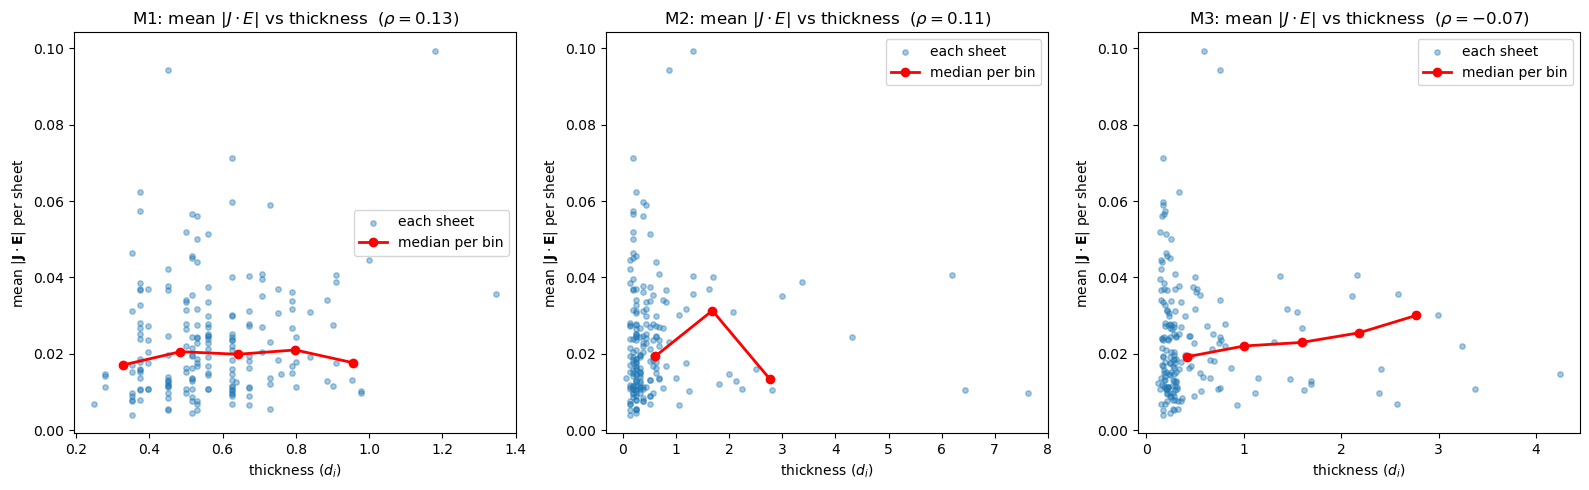


=== J.E vs thickness  (beta_p=1, t=200) ===
 method     N   rho(mean)   rho(sum)   rho(|.|)
     M1   188       0.166      0.181      0.133
     M2   188       0.066      0.094      0.108
     M3   186       0.101      0.110     -0.069

Saved figure and M1 CSV for beta=1, t=200.


In [5]:
# ============================================================
#  J . E  vs  current-sheet THICKNESS  (one beta)
#  ------------------------------------------------------------
#  CONNECTIVITY: a SINGLE 8-connected labeling (measure.label, connectivity=2)
#  is used by all three thickness methods AND by J.E, so every per-sheet
#  quantity shares one region index space. (Previously M1 used skimage 8-conn
#  while M2/M3 used scipy 4-conn, so they measured different sheets.)
#
#  Filters B and E, builds J.E, detects the sheets, runs YOUR thickness
#  methods (M1/M2/M3, algorithms unchanged), then pairs a per-sheet J.E with
#  each thickness and plots J.E vs thickness (scatter + binned medians).
#
#  Per-sheet J.E measured three ways: mean signed, integrated sum, mean |.|.
#  Assumes E files named like your B files: Ex_ApJ_t{time}.h5 etc.
#  Needs from your session: iterative_filtering3D, partial_x_fft, partial_y_fft,
#                           detect_current_sheets
# ============================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
from scipy.stats import spearmanr

# -----------------------------
# USER SETTINGS
# -----------------------------
beta    = 1                        # one run only
time    = 200
sim_tag = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"
cache_dir = str(CACHE / "filtered_cache")
os.makedirs(cache_dir, exist_ok=True)

px_per_di = 16.0
dx = dy   = 0.0625

if beta == 0.0625:
    n_iter, Xi = 1, 1.6
elif beta == 1:
    n_iter, Xi = 2, 2.0
else:
    n_iter, Xi = 3, 2.0


# -----------------------------
# FILTER B (reuses your existing cache) and E
# -----------------------------
cache_B = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
if os.path.exists(cache_B):
    print("Loading cached filtered B ...")
    d = np.load(cache_B); Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
else:
    print("Filtering B (slow) ...")
    Bx_f, By_f, Bz_f = iterative_filtering3D(load("Bx"), load("By"), load("Bz"), n_iter, Xi=Xi)
    np.savez_compressed(cache_B, Bx=Bx_f, By=By_f, Bz=Bz_f)

cache_E = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}_E.npz"
if os.path.exists(cache_E):
    print("Loading cached filtered E ...")
    d = np.load(cache_E); Ex_f, Ey_f, Ez_f = d["Ex"], d["Ey"], d["Ez"]
else:
    print("Filtering E (slow) ...")
    Ex_f, Ey_f, Ez_f = iterative_filtering3D(load("Ex"), load("Ey"), load("Ez"), n_iter, Xi=Xi)
    np.savez_compressed(cache_E, Ex=Ex_f, Ey=Ey_f, Ez=Ez_f)

# -----------------------------
# CURRENT DENSITY, J.E, and the sheet mask (your detection)
# -----------------------------
Jx = partial_y_fft(Bz_f, dx)
Jy = -partial_x_fft(Bz_f, dy)
Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
J2 = np.abs(Jz)
JdotE = Jx * Ex_f + Jy * Ey_f + Jz * Ez_f

sheets = detect_current_sheets(J2)
mask = np.zeros_like(J2)
for sheet in sheets:
    for (i, j) in sheet:
        mask[i, j] = 1
struct = morphology.disk(1)
mask = morphology.binary_opening(mask, struct)
mask = morphology.binary_closing(mask, struct)
cleaned_mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)


# =====================================================================
# ONE labeling for everything (8-connectivity)
# =====================================================================
labeled_mask = measure.label(cleaned_mask, connectivity=2)
num_regions = labeled_mask.max()
print(f"[t={time}] regions (8-connectivity):", num_regions)

# one current-density peak per region (M2/M3 sample directions from these)
max_coords, max_values = [], []
for i in range(1, num_regions + 1):
    region_mask = (labeled_mask == i)
    region_vals = J2[region_mask]
    if region_vals.size == 0:
        continue
    max_pos = np.argmax(np.abs(region_vals))
    max_values.append(region_vals[max_pos])
    xs_r, ys_r = np.where(region_mask)
    max_coords.append((xs_r[max_pos], ys_r[max_pos]))
# max_coords[k]  <->  region (k+1)


# =====================================================================
# THICKNESS METHODS  (algorithms UNCHANGED; all use `labeled_mask`)
# =====================================================================

# ----- M1: distance transform, per region -----
thicknesses_m1 = []
for label_id in range(1, num_regions + 1):
    region = (labeled_mask == label_id)
    dist = ndi.distance_transform_edt(region)
    thicknesses_m1.append(2 * dist.max())
# thicknesses_m1[k]  <->  region (k+1)  (same index as max_coords[k])

# ----- M2: steepest-descent walk -----
sigma = 3
J2_smooth = gaussian_filter(J2, sigma=sigma)
dJdx, dJdy = np.gradient(J2_smooth)

descent_dirs = []
for (x, y) in max_coords:
    grad = np.array([dJdx[x, y], dJdy[x, y]])
    if np.allclose(grad, 0):
        descent_dirs.append(np.array([0.0, 0.0]))
    else:
        descent_dirs.append(-grad / np.linalg.norm(grad))

distances = []
step_size = 1
max_steps = 1000
for (x0, y0), (dx, dy) in zip(max_coords, descent_dirs):
    x0f, y0f = float(x0), float(y0)
    xf, yf, steps = x0f, y0f, 0
    while steps < max_steps:
        xf_new, yf_new = xf + dx*step_size, yf + dy*step_size
        xi, yi = int(round(xf_new)), int(round(yf_new))
        if (xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
            break
        if not cleaned_mask[xi, yi]:
            break
        xf, yf = xf_new, yf_new; steps += 1
    dist_forward = np.hypot(xf - x0f, yf - y0f)

    xb, yb, steps = x0f, y0f, 0
    while steps < max_steps:
        xb_new, yb_new = xb - dx*step_size, yb - dy*step_size
        xi, yi = int(round(xb_new)), int(round(yb_new))
        if (xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
            break
        if not cleaned_mask[xi, yi]:
            break
        xb, yb = xb_new, yb_new; steps += 1
    dist_backward = np.hypot(xb - x0f, yb - y0f)

    distances.append((dist_backward, dist_forward))
# distances[k]  <->  region (k+1)

# ----- M3: FWHM via Gaussian fit along descent (sub-pixel, adaptive window) -----
max_len, subpix_step, margin_frac, min_half = 60, 0.5, 0.5, 6.0

fwhms = []
for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
    if dx == 0 and dy == 0:
        fwhms.append(np.nan); continue

    len_f = _walk_to_mask_edge(cleaned_mask, x, y,  dx,  dy)
    len_b = _walk_to_mask_edge(cleaned_mask, x, y, -dx, -dy)
    half_f = min(max_len, max(min_half, len_f * (1.0 + margin_frac)))
    half_b = min(max_len, max(min_half, len_b * (1.0 + margin_frac)))

    xs = np.arange(-half_b, half_f + subpix_step, subpix_step)
    x_coord, y_coord = x + xs * dx, y + xs * dy
    vals = ndi.map_coordinates(J2, np.vstack([x_coord, y_coord]), order=1, mode='grid-wrap')

    if len(vals) < 4:
        fwhms.append(np.nan); continue

    B0 = float(vals.min()); A0 = float(vals.max() - vals.min())
    if A0 <= 0:
        fwhms.append(np.nan); continue
    mu0 = float(xs[np.argmax(vals)])

    above = np.where(vals >= B0 + 0.5 * A0)[0]
    if above.size >= 2:
        sigma0 = max(1.0, (xs[above[-1]] - xs[above[0]]) / 2.3548)
    else:
        sigma0 = max(2.0, (half_f + half_b) / 6.0)
    span = float(xs.max() - xs.min())
    sigma0 = min(sigma0, 0.99 * span)

    bounds = ([0.0, xs.min() - 1.0, 1e-3, -np.inf], [np.inf, xs.max() + 1.0, span, np.inf])
    try:
        popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0], bounds=bounds, maxfev=10000)
        fwhms.append(2.0 * np.sqrt(2.0 * np.log(2.0)) * abs(popt[2]))
    except (RuntimeError, ValueError):
        fwhms.append(np.nan)
# fwhms[k]  <->  region (k+1)


# =====================================================================
# J . E  per region (computed ONCE; shared by all methods)
# =====================================================================
je_mean, je_sum, je_abs = [], [], []
for label_id in range(1, num_regions + 1):
    vals = JdotE[labeled_mask == label_id]
    je_mean.append(vals.mean()); je_sum.append(vals.sum()); je_abs.append(np.abs(vals).mean())
je_mean = np.array(je_mean); je_sum = np.array(je_sum); je_abs = np.array(je_abs)
# je_*[k]  <->  region (k+1)  -> aligned with thicknesses_m1, distances, fwhms


# =====================================================================
# Apply YOUR per-method filters jointly (thickness + J.E stay aligned)
# =====================================================================
t_m1 = np.array(thicknesses_m1)
s1 = t_m1 > 0
th_m1 = t_m1[s1] / px_per_di
JE_m1 = (je_mean[s1], je_sum[s1], je_abs[s1])

t_m2 = np.array([d[0] + d[1] for d in distances])
s2 = t_m2 > 0
th_m2 = t_m2[s2] / px_per_di
JE_m2 = (je_mean[s2], je_sum[s2], je_abs[s2])

t_m3 = np.array(fwhms)
s3 = ~np.isnan(t_m3)
s3[s3] = (t_m3[s3] > 0) & (t_m3[s3] <= 100)
th_m3 = t_m3[s3] / px_per_di
JE_m3 = (je_mean[s3], je_sum[s3], je_abs[s3])


# =====================================================================
# PLOT: mean J.E vs thickness for M1, M2, M3  (+ binned medians)
# =====================================================================
panels = [("M1", th_m1, JE_m1), ("M2", th_m2, JE_m2), ("M3", th_m3, JE_m3)]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, th, (jmean, jsum, jabs)) in zip(axes, panels):
    if len(th) == 0:
        ax.set_title(f"{name}: no sheets"); continue
    ax.scatter(th, jabs, s=15, alpha=0.4, label="each sheet")
    bins = np.linspace(th.min(), th.max(), 8)
    cen, med = [], []
    for k in range(len(bins) - 1):
        sel = (th >= bins[k]) & (th < bins[k + 1])
        if sel.sum() >= 3:
            cen.append(0.5 * (bins[k] + bins[k + 1])); med.append(np.median(jabs[sel]))
    ax.plot(cen, med, "o-", color="red", lw=2, label="median per bin")
    rho, _ = spearmanr(th, jabs)
    ax.set_title(f"{name}: mean $|J\\cdot E|$ vs thickness  ($\\rho={rho:.2f}$)")
    ax.set_xlabel(r"thickness $(d_i)$"); ax.set_ylabel(r"mean $|\mathbf{J}\cdot\mathbf{E}|$ per sheet")
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / f"JdotE_mod_vs_thickness_beta{beta}_t{time}.png", dpi=300)
plt.show()


# =====================================================================
# Correlations (all three J.E measures) + per-sheet CSV for M1
# =====================================================================
print(f"\n=== J.E vs thickness  (beta_p={beta}, t={time}) ===")
print(f"{'method':>7} {'N':>5} {'rho(mean)':>11} {'rho(sum)':>10} {'rho(|.|)':>10}")
for name, th, (jmean, jsum, jabs) in panels:
    if len(th) < 3:
        print(f"{name:>7} {len(th):>5}   (too few)"); continue
    print(f"{name:>7} {len(th):>5} {spearmanr(th, jmean)[0]:>11.3f} "
          f"{spearmanr(th, jsum)[0]:>10.3f} {spearmanr(th, jabs)[0]:>10.3f}")

with open(f"JdotE_vs_thickness_M1_beta{beta}_t{time}.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["thickness_di", "JE_mean", "JE_sum", "JE_absmean"])
    for i in range(len(th_m1)):
        w.writerow([th_m1[i], JE_m1[0][i], JE_m1[1][i], JE_m1[2][i]])

print(f"\nSaved figure and M1 CSV for beta={beta}, t={time}.")


--- beta = 1, t = 200 ---
found 244 sheets

pooled 244 sheets from 1 snapshot(s)


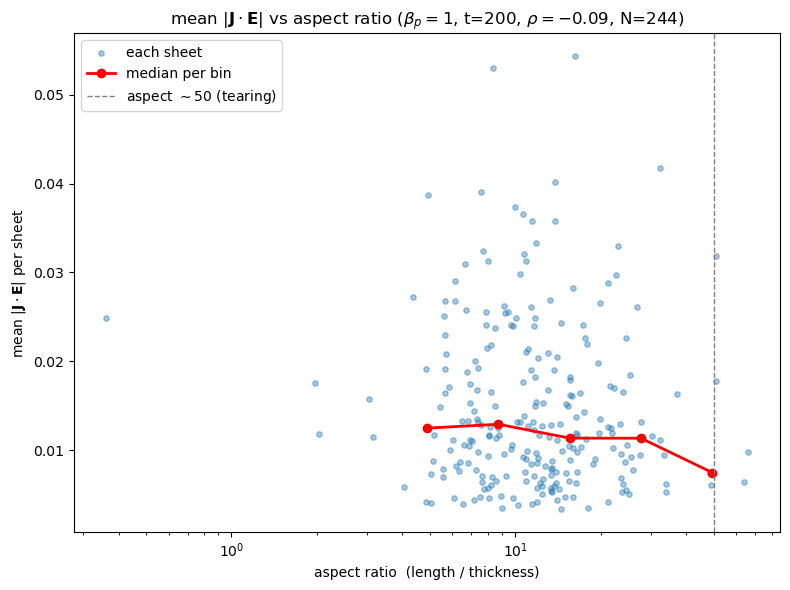


--- mean |J.E| vs aspect ratio ---
sheets                 : 244
aspect ratio           : median = 11.63  (range 0.36-65.92)
mean |J.E| per sheet   : median = 1.192e-02
Spearman rho           : -0.088
sheets with aspect > 50: 4

Saved in:  cs_je_vs_aspect_beta1/


In [3]:
# ============================================================
#  mean |J . E| per sheet  vs  ASPECT RATIO  (length / thickness)
#  ------------------------------------------------------------
#  Combines your two pipelines. For one beta (optionally pooled over times):
#    filter B and E  ->  J = curl(B),  J.E = J . E
#    detect sheets (your pipeline)  ->  ONE 8-connected labeling
#    per region:  skeleton length, caliper, M1 thickness  ->  aspect = length/thickness
#                 mean |J.E|  (and mean signed, integrated, for the CSV)
#    plot: mean |J.E| per sheet  vs  aspect ratio (scatter + binned medians)
#
#  NOTE: length and J.E are built from the SAME filtered B, so both must use the
#  same filter parameters. This uses the J.E code's table (cache 'filtered_cache').
#  Assumes E files named like your B files: Ex_ApJ_t{time}.h5 etc.
#  Needs from your session: iterative_filtering3D, partial_x_fft, partial_y_fft,
#                           detect_current_sheets
# ============================================================

# -----------------------------
# USER SETTINGS
# -----------------------------
beta      = 1                          # one run
times     = [200]                      # pool over snapshots, e.g. [200, 205, 210]
sim_tag   = "ApJ"
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

cache_dir = str(CACHE / "filtered_cache")
out_dir   = str(RESULTS / f"cs_je_vs_aspect_beta{beta}")

px_per_di        = 16.0
CONNECTIVITY     = 2                    # 8-connectivity, shared by geometry and J.E
MIN_LENGTH_DI    = 0.0                  # drop sheets shorter than this
ASPECT_THRESHOLD = 50                   # reference line (tearing/plasmoid regime)
dx = dy          = 0.0625

os.makedirs(cache_dir, exist_ok=True)
os.makedirs(out_dir, exist_ok=True)


def filter_params(b):
    if b == 0.0625: return 3, 2.0
    if b == 0.25:   return 3, 2.3
    if b == 1:      return 3, 2.5
    if b == 4:      return 3, 2.7
    return 3, 3.0


def load(tag, time):
    with h5py.File(f"{base_path}{tag}_{sim_tag}_t{time}.h5", "r") as f:
        return f["DS1"][:].T


# ============================================================
# Geometry helpers (unchanged from your length code)
# ============================================================
def skeleton_length(region, step=1.0, fill_holes=True):
    """Longest path along the region's skeleton (branches ignored)."""
    region = np.asarray(region, bool)
    xs, ys = np.where(region)
    if len(xs) == 0:
        return 0.0
    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1
    reg = region[x0:x1, y0:y1]
    if fill_holes:
        reg = ndi.binary_fill_holes(reg)
    skel = skeletonize(reg)
    coords = np.argwhere(skel)
    n = len(coords)
    if n < 2:
        return 0.0
    idx = {(int(i), int(j)): k for k, (i, j) in enumerate(coords)}
    rows, cols, wts = [], [], []
    for k, (i, j) in enumerate(coords):
        for di in (-1, 0, 1):
            for dj in (-1, 0, 1):
                if di == 0 and dj == 0:
                    continue
                m = idx.get((int(i) + di, int(j) + dj))
                if m is not None and m > k:
                    w = np.hypot(di, dj) * step
                    rows += [k, m]; cols += [m, k]; wts += [w, w]
    graph = csr_matrix((wts, (rows, cols)), shape=(n, n))
    d0 = dijkstra(graph, indices=0, directed=False); d0[np.isinf(d0)] = -1
    a = int(np.argmax(d0))
    da = dijkstra(graph, indices=a, directed=False); da[np.isinf(da)] = -1
    return float(da.max())


# ============================================================
# MAIN LOOP over times -> per-sheet (aspect ratio, J.E) rows
# ============================================================
step_di = 1.0 / px_per_di
rows_csv = []                            # [time, id, L, cal, th, aspect, tort, je_mean, je_sum, je_abs]

for time in times:
    print(f"\n--- beta = {beta}, t = {time} ---", flush=True)
    n_iter, Xi = filter_params(beta)

    # ----- filter B (reuses your cache) -----
    cache_B = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_B):
        d = np.load(cache_B); Bx_f, By_f, Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        print("Filtering B (slow) ...", flush=True)
        Bx_f, By_f, Bz_f = iterative_filtering3D(load("Bx", time), load("By", time),
                                                 load("Bz", time), n_iter, Xi=Xi)
        np.savez_compressed(cache_B, Bx=Bx_f, By=By_f, Bz=Bz_f)

    # ----- filter E -----
    cache_E = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}_E.npz"
    if os.path.exists(cache_E):
        d = np.load(cache_E); Ex_f, Ey_f, Ez_f = d["Ex"], d["Ey"], d["Ez"]
    else:
        print("Filtering E (slow) ...", flush=True)
        Ex_f, Ey_f, Ez_f = iterative_filtering3D(load("Ex", time), load("Ey", time),
                                                 load("Ez", time), n_iter, Xi=Xi)
        np.savez_compressed(cache_E, Ex=Ex_f, Ey=Ey_f, Ez=Ez_f)

    # ----- J, J.E, and the sheet mask -----
    Jx = partial_y_fft(Bz_f, dx)
    Jy = -partial_x_fft(Bz_f, dy)
    Jz = partial_x_fft(By_f, dy) - partial_y_fft(Bx_f, dx)
    J2 = np.abs(Jz)
    JdotE = Jx * Ex_f + Jy * Ey_f + Jz * Ez_f

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    cleaned_mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)

    labeled = measure.label(cleaned_mask, connectivity=CONNECTIVITY)
    n_sheets = labeled.max()
    print(f"found {n_sheets} sheets", flush=True)

    # ----- per region: geometry (aspect) + J.E -----
    for label_id in range(1, n_sheets + 1):
        region = (labeled == label_id)
        L  = skeleton_length(region, step=step_di)
        if L < MIN_LENGTH_DI:
            continue
        th  = thickness_m1(region, step=step_di)
        cal = caliper_length(region, step=step_di)
        aspect = L / th  if th  > 0 else np.nan
        tort   = L / cal if cal > 0 else np.nan

        vals = JdotE[region]
        je_mean, je_sum, je_abs = vals.mean(), vals.sum(), np.abs(vals).mean()

        rows_csv.append([time, label_id, L, cal, th, aspect, tort, je_mean, je_sum, je_abs])

rows_csv = np.array(rows_csv, dtype=float) if rows_csv else np.empty((0, 10))
if len(rows_csv) == 0:
    raise SystemExit("No sheets measured (check paths / times).")

# unpack + keep sheets with a valid, positive aspect ratio
aspect = rows_csv[:, 5]
je_abs = rows_csv[:, 9]
good   = np.isfinite(aspect) & (aspect > 0)
aspect, je_abs = aspect[good], je_abs[good]
print(f"\npooled {len(aspect)} sheets from {len(times)} snapshot(s)")


# ============================================================
# PLOT: mean |J.E| per sheet vs aspect ratio
# ============================================================
plt.figure(figsize=(8, 6))
plt.scatter(aspect, je_abs, s=15, alpha=0.4, label="each sheet")

# binned medians (log-spaced aspect bins)
abins = np.logspace(np.log10(aspect.min()), np.log10(aspect.max()), 10)
cen, med = [], []
for k in range(len(abins) - 1):
    sel = (aspect >= abins[k]) & (aspect < abins[k + 1])
    if sel.sum() >= 3:
        cen.append(np.sqrt(abins[k] * abins[k + 1])); med.append(np.median(je_abs[sel]))
plt.plot(cen, med, "o-", color="red", lw=2, label="median per bin")

plt.axvline(ASPECT_THRESHOLD, color="gray", ls="--", lw=1,
            label=fr"aspect $\sim{ASPECT_THRESHOLD}$ (tearing)")
plt.xscale("log")
rho, _ = spearmanr(aspect, je_abs)
tt = f"t={times[0]}" if len(times) == 1 else f"pooled t={times[0]}$-${times[-1]}"
plt.title(rf"mean $|\mathbf{{J}}\cdot\mathbf{{E}}|$ vs aspect ratio "
          rf"($\beta_p={beta}$, {tt}, $\rho={rho:.2f}$, N={len(aspect)})")
plt.xlabel("aspect ratio  (length / thickness)")
plt.ylabel(r"mean $|\mathbf{J}\cdot\mathbf{E}|$ per sheet")
plt.legend()
plt.tight_layout()
plt.savefig(f"{out_dir}/je_mod_vs_aspect_beta{beta}.png", dpi=300)
plt.show()


# ============================================================
# CSV + summary
# ============================================================
with open(f"{out_dir}/je_vs_aspect_beta{beta}.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["time", "sheet_id", "length_di", "caliper_di", "thickness_di",
                "aspect_ratio", "tortuosity", "JE_mean", "JE_sum", "JE_absmean"])
    for r in rows_csv:
        w.writerow([int(r[0]), int(r[1]), r[2], r[3], r[4], r[5], r[6], r[7], r[8], r[9]])

print("\n--- mean |J.E| vs aspect ratio ---")
print(f"sheets                 : {len(aspect)}")
print(f"aspect ratio           : median = {np.median(aspect):.2f}  (range {aspect.min():.2f}-{aspect.max():.2f})")
print(f"mean |J.E| per sheet   : median = {np.median(je_abs):.3e}")
print(f"Spearman rho           : {rho:.3f}")
print(f"sheets with aspect > {ASPECT_THRESHOLD}: {int(np.sum(aspect > ASPECT_THRESHOLD))}")
print(f"\nSaved in:  {out_dir}/")